**Before starting this practical session**:

1. **Change the runtime type on Google Colab**: `Runtime > Change runtime type > T4 GPU`
2. **Install the packages below**:

In [1]:
! pip install lightning torchmetrics torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 17.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 23.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 28.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [lightning]


3. Run this code to suppress some messages and warnings that may be displayed.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# *Inpainting* of masked images

In this notebook, you will work on the [MNIST](https://en.wikipedia.org/wiki/MNIST_database) dataset, consisting of images of handwritten digits.

[*Inpainting*](https://en.wikipedia.org/wiki/Inpainting) consists in reconstructing damaged images or filling in missing parts of images.
The example below is taken from the Wikipedia page on inpainting.
On the left is the damaged image and on the right is the reconstructed image.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/f8/Restoration.jpg" width=800 />

**The goal is to reconstruct the images from the damaged images.**

## Downloading and visualizing the data

The `load_dataset()` function defined below downloads the dataset.

In [3]:
import torch


def load_dataset(train, path="data"):
    """Load the data set.

    Parameters
    ----------
    train : bool
        If True, returns the training set. Otherwise, returns the validation set.

    path : str
        Path to the directory.

    Returns
    -------
    x : Tensor, shape = (n_samples, n_channels, height, width)
        Original images.
    """
    from torchvision.datasets import MNIST

    # (Down)load the data set
    dataset = MNIST(root=path, download=True, train=train)

    # Format the tensors
    x = torch.unsqueeze(dataset.data / 255, 1)

    return x

Simply call this function to retrieve the training and validation sets.

In [4]:
x_train_original = load_dataset(train=True)
x_val_original = load_dataset(train=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 408kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.78MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.1MB/s]


### Question 1

Determine the number of samples in the training and validation sets.
Determine the number of channels and the image size.

In [8]:
n = x_train_original.shape[0]
print(f"There are {n} samples")

There are 60000 samples


### Question 2

What are the minimum and maximum pixel values in the training set?

In [10]:
min_train = x_train_original.min()
max_train = x_train_original.max()

print(f"The minimum value is: {min_train}")
print(f"The maximum value is: {max_train}")

The minimum value is: 0.0
The maximum value is: 1.0


The dataset only contains the original (non-damaged) images.
We will therefore need to implement our own image damaging technique.
We will implement something simple: each pixel is replaced, with probability $p$, by a black pixel (i.e., a pixel whose value is $0.0$).
One possible implementation of this approach is as follows:

1. Generate a tensor of uniform random variables on the interval $[0, 1]$ with the same shape as the input tensor. To do this, you can use the [`torch.rand_like()`](https://docs.pytorch.org/docs/stable/generated/torch.rand_like.html) function.
2. Transform this tensor of uniform random variables into a mask, i.e., a tensor of booleans, indicating which elements of the input tensor to keep: the elements kept are those whose uniform random variable is greater than $p$.
3. Multiply the input tensor by the mask: the elements for which the mask is `True` are kept, and the elements for which the mask is `False` are replaced with $0$.


The `deteriorate_images()` function defined below performs this deterioration.

### Question 3

Complete the missing code in the `deteriorate_images()` function.

In [18]:
def deteriorate_images(x_original, p=0.5):
    """Deteriorate images.

    Parameters
    ----------
    x_original : Tensor, shape = (n_samples, n_channels, height, width)
        Original images.

    p : float, default = 0.5
        Probability of replacing each pixel with a black pixel.

    Returns
    -------
    x_deteriorated : Tensor, shape = (n_images, n_channels, height, width)
        Deteriorated images.
    """
    ### BEGIN TODO ###
    mask = (torch.rand_like(x_original) <= 0.5)
    x_deteriorated = x_original * mask
    ### END TODO
    return x_deteriorated

We now call the `deteriorate_images()` function, with `p=0.5`, to create damaged images on the training and validation sets:

In [19]:
x_train_deteriorated = deteriorate_images(x_train_original)
x_val_deteriorated = deteriorate_images(x_val_original)

The `plot_original_and_deteriorated_images()` function defined below visualizes this operation: it takes a batch of original images as input, applies the transformation, and displays the original and damaged images.

In [21]:
import matplotlib.pyplot as plt


def plot_original_and_deteriorated_images(x_original, x_deteriorated):
    """Plot the original and deteriorated images.

    Parameters
    ----------
    x_original : Tensor, shape = (n_images, n_channels, height, width)
        Original images.

    x_deteriorated : Tensor, shape = (n_images, n_channels, height, width)
        Deteriorated images.
    """
    # Get the number of images
    n_images = x_original.shape[0]

    # Instantiate the figure
    plt.figure(figsize=(6.5, 3 * n_images))

    # For each row
    for row in range(n_images):

        # Plot the original image
        plt.subplot(n_images, 2, 1 + row * 2)
        plt.imshow(x_original[row, 0], cmap="gray", vmin=0.0, vmax=1.0)
        plt.title("Original image")
        plt.axis("off");

        # Plot the deteriorated image
        plt.subplot(n_images, 2, 2 + row * 2)
        plt.imshow(x_deteriorated[row, 0], cmap="gray", vmin=0.0, vmax=1.0)
        plt.title("Deteriorated image")
        plt.axis("off");

### Question 4

Call the `plot_original_and_deteriorated_images()` function to display a few original and damaged images from the training and validation sets.

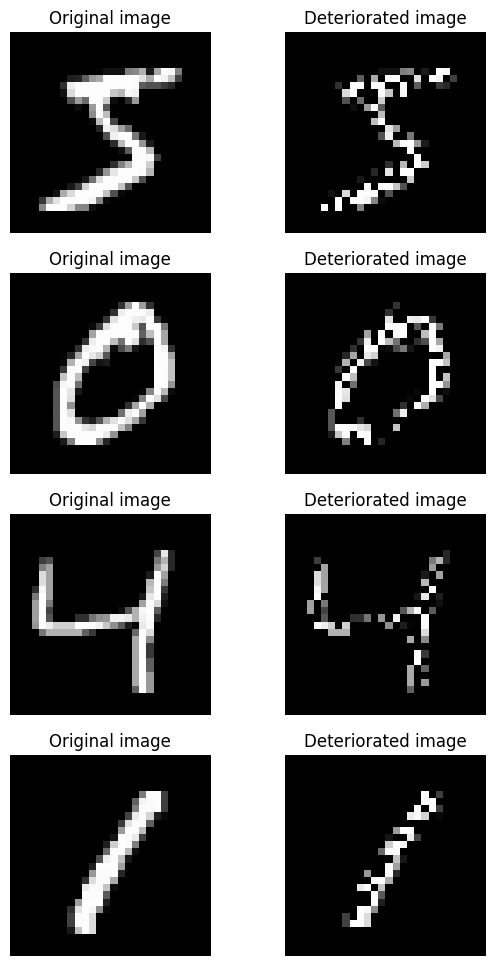

In [23]:
plot_original_and_deteriorated_images(x_train_original[:4,...], x_train_deteriorated[:4,...])

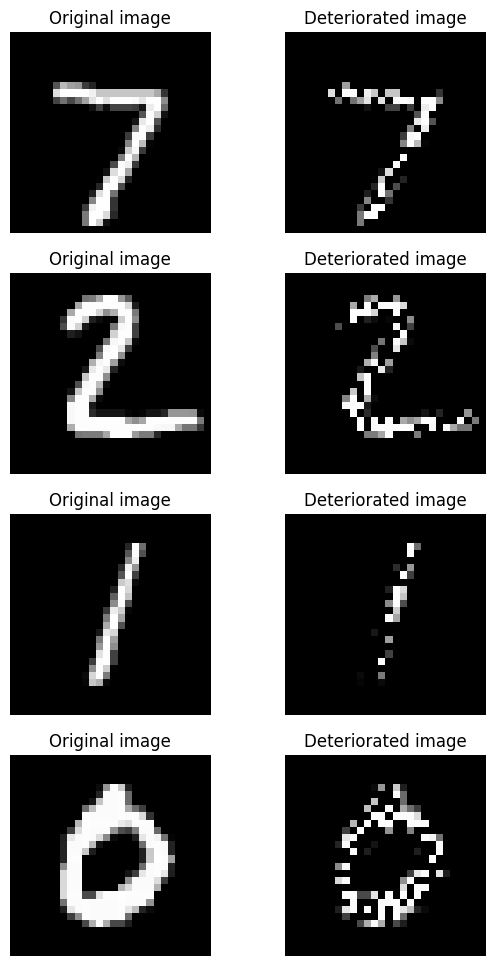

In [25]:
plot_original_and_deteriorated_images(x_val_original[:4,...], x_val_deteriorated[:4,...])

We will evaluate the models' performance using the mean squared error:
$$
  \text{MSE} = \frac{1}{n H W} \sum_{i=1}^n \sum_{j=1}^H \sum_{k=1}^W \left( X_{i, j, k} - \hat{X}_{i, j, k} \right)^2
$$
where $n$ is the number of images, $H$ is the height (i.e., the number of rows), and $W$ is the width (i.e., the number of columns).


A truly trivial model consists in predicting only black images (i.e., images whose pixels are all equal to $0.0$):
$$
    \forall i, j, k, \; \hat{X}_{i, j, k} = 0.0
$$

### Question 5

Compute the mean squared errors on the training and validation sets for this approach. As a reminder:

* the *power* operator in Python is obtained with two asterisks: `2.0 ** 3` means $2.0^3$; this operator also works on tensors and applies the power to each element of the tensor;
* the mean value of a tensor can be computed with the [`torch.Tensor.mean()`](https://docs.pytorch.org/docs/stable/generated/torch.Tensor.mean.html) method or the [`torch.mean()`](https://docs.pytorch.org/docs/stable/generated/torch.mean.html) function.

In [28]:
mse_train_trivial = 1 / (x_train_original.shape[0] * x_train_original.shape[2] * x_train_original.shape[3]) * x_train_original.pow(2).sum()
mse_val_trivial = 1 / (x_val_original.shape[0] * x_val_original.shape[2] * x_val_original.shape[3]) * x_val_original.pow(2).sum()

print(f"training MSE: {mse_train_trivial}")
print(f"validation MSE: {mse_val_trivial}")

training MSE: 0.11200256645679474
validation MSE: 0.11395809799432755


Another trivial model consists in keeping the damaged images as they are.

### Question 6

Compute the mean squared errors on the training and validation sets for this approach.

In [59]:
mse_train_asis = 1 / (x_train_original.shape[0] * x_train_original.shape[2] * x_train_original.shape[3]) * (x_train_original - x_train_deteriorated).pow(2).sum()
mse_val_asis = 1 / (x_val_original.shape[0] * x_val_original.shape[2] * x_val_original.shape[3]) * (x_val_original - x_val_deteriorated).pow(2).sum()

print(f"training MSE: {mse_train_asis}")
print(f"validation MSE: {mse_val_asis}")

training MSE: 0.05595710873603821
validation MSE: 0.05691808462142944


Before training a neural network, we will try a simple approach.
We will use a uniform blurring kernel: we replace the value of each pixel with the uniform average of its pixel and its neighboring pixels.
The `box_blur_convolution()` function defined below implements this approach.

In [30]:
def box_blur_convolution(x_deteriorated, kernel_size=3):
    """Box blur convolution.

    Parameters
    ----------
    x_deteriorated : Tensor, shape = (n_images, n_channels, height, width)
        Deteriorated images.

    kernel_size : int, default = 3
        Kernel size. Must be an odd integer greater than or equal to 3.
        The same value is used in both dimensions (i.e., the kernel is square).

    Returns
    -------
    x_convolved : Tensor, shape = (n_images, n_channels, height, width)
        Convolved images.
    """
    if not (isinstance(kernel_size, int) and (kernel_size > 2) and (kernel_size % 2 == 1)):
        raise ValueError("'kernel_size' must be an odd integer greater than or equal to 3.")

    kernel = torch.ones(1, 1, kernel_size, kernel_size) / kernel_size ** 2
    conv = torch.nn.Conv2d(1, 1, kernel_size, padding="same", bias=False)
    conv.weight = torch.nn.Parameter(kernel, requires_grad=False)
    x_convolved = conv(x_deteriorated)
    return x_convolved

We call this function to apply the transformation on the training and validation sets:

In [31]:
x_train_reconstructed = box_blur_convolution(x_train_deteriorated)
x_val_reconstructed = box_blur_convolution(x_val_deteriorated)

### Question 7

Compute the mean squared errors on these two sets.

In [58]:
mse_train_unif = 1 / (x_train_original.shape[0] * x_train_original.shape[2] * x_train_original.shape[3]) * (x_train_original - x_train_reconstructed).pow(2).sum()
mse_val_unif = 1 / (x_val_original.shape[0] * x_val_original.shape[2] * x_val_original.shape[3]) * (x_val_original - x_val_reconstructed).pow(2).sum()

print(f"training MSE: {mse_train_unif}")
print(f"validation MSE: {mse_val_unif}")

training MSE: 0.044671058654785156
validation MSE: 0.045072611421346664


We define the `plot_original_deteriorated_reconstructed_images()` function to display original images, damaged images, and reconstructed images.

In [33]:
def plot_original_deteriorated_reconstructed_images(
    x_original, x_deteriorated, x_reconstructed
):
    """Plot the original, deteriorated, and reconstructed images.

    Parameters
    ----------
    x_original : Tensor, shape = (n_images, n_channels, height, width)
        Original images.

    x_deteriorated : Tensor, shape = (n_images, n_channels, height, width)
        Deteriorated images.

    x_reconstructed : Tensor, shape = (n_images, n_channels, height, width)
        Reconstructed images.
    """
    # Get the number of images
    n_images = x_original.shape[0]

    # Instantiate the figure
    plt.figure(figsize=(9.5, 3 * n_images))

    # For each row
    for row in range(n_images):

        # Plot the original image
        plt.subplot(n_images, 3, 1 + row * 3)
        plt.imshow(x_original[row, 0], cmap="gray", vmin=0.0, vmax=1.0)
        plt.title("Original image")
        plt.axis("off");

        # Plot the deteriorated image
        plt.subplot(n_images, 3, 2 + row * 3)
        plt.imshow(x_deteriorated[row, 0], cmap="gray", vmin=0.0, vmax=1.0)
        plt.title("Deteriorated image")
        plt.axis("off");

        # Plot the reconstructed image
        plt.subplot(n_images, 3, 3 + row * 3)
        plt.imshow(x_reconstructed[row, 0], cmap="gray", vmin=0.0, vmax=1.0)
        plt.title("Reconstructed image")
        plt.axis("off");

### Question 8

Call the `plot_original_deteriorated_reconstructed_images()` function to display original images, damaged images, and reconstructed images on the validation set. What do you notice?

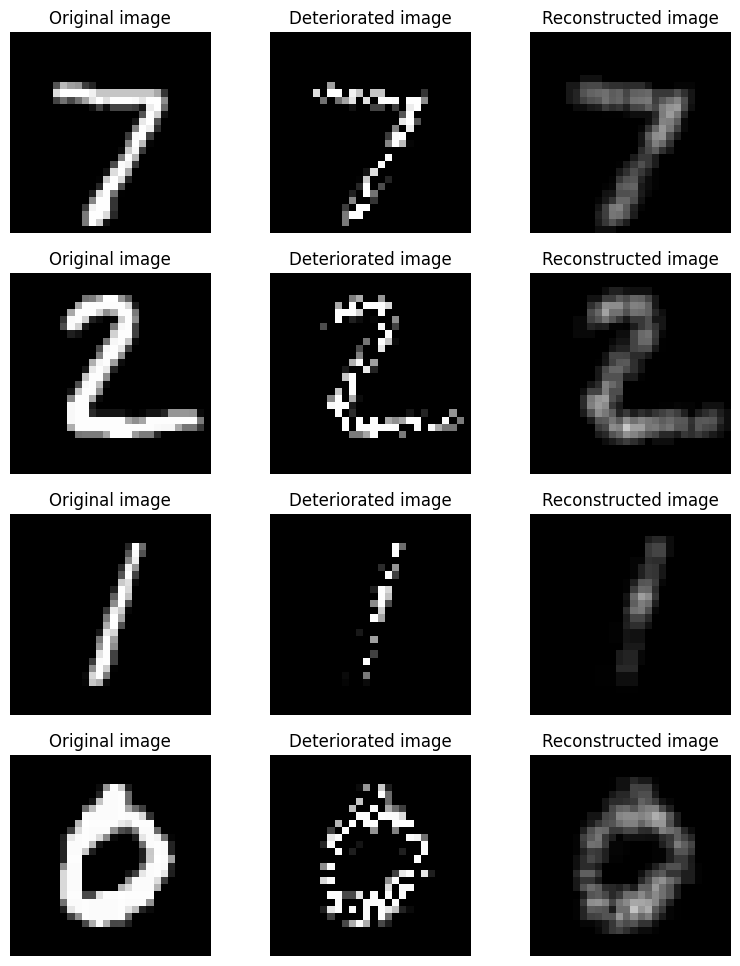

In [34]:
plot_original_deteriorated_reconstructed_images(x_val_original[:4, ...], x_val_deteriorated[:4, ...], x_val_reconstructed[:4, ...])

**Answer**: The reconstructed images are much darker. This is because the uniform kernel spreads the color of the "off" pixels to the white ones.

### Question 9

To confirm your answer to the previous question, display the pixel distribution of the original images on one hand and of the reconstructed images on the other hand, on the training set.
You can use the [`matplotlib.pyplot.hist()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) function.

(array([3.7357927e+07, 2.9066480e+06, 2.4447540e+06, 1.9328030e+06,
        1.2858780e+06, 7.0294700e+05, 2.9792500e+05, 9.1323000e+04,
        1.8105000e+04, 1.6900000e+03]),
 array([0.        , 0.1       , 0.2       , 0.30000001, 0.40000001,
        0.5       , 0.60000002, 0.69999999, 0.80000001, 0.90000004,
        1.        ]),
 <BarContainer object of 10 artists>)

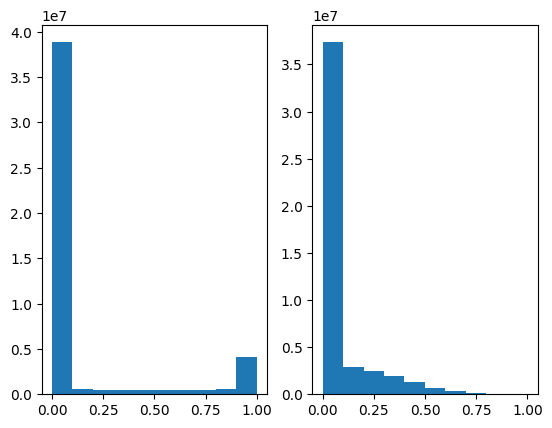

In [41]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2)

axes[0].hist(x_train_original.flatten())
axes[1].hist(x_train_reconstructed.flatten())

To try to address this issue, we will normalize the images so that the maximum pixel value of each reconstructed image is equal to $1.0$. To do this, we will simply divide each pixel of a reconstructed image by the maximum pixel value of that reconstructed image.

### Question 10

1. Apply this transformation to the reconstructed images of the training and validation sets.
2. Display the new pixel distribution on the training set.
3. Display a few normalized reconstructed images on the validation set using the `plot_original_deteriorated_reconstructed_images()` function.
4. Compute the mean squared errors on both sets.
5. Comment on the results obtained.

To answer the first question, you can use the [`torch.amax()`](https://docs.pytorch.org/docs/stable/generated/torch.amax.html) function or the [`torch.Tensor.amax()`](https://docs.pytorch.org/docs/stable/generated/torch.Tensor.amax.html) method.
Read the documentation, especially for the `dim` and `keepdim` parameters.
It is possible to answer the question without a `for` loop thanks to [*broadcasting*](https://docs.pytorch.org/docs/stable/notes/broadcasting.html).

In [50]:
max_values_train = x_train_reconstructed.amax((2,3), keepdim=True)
max_values_val = x_val_reconstructed.amax((2,3), keepdim=True)
max_values_train.shape
max_values_val.shape

torch.Size([10000, 1, 1, 1])

In [52]:
x_train_reconstructed_renorm = x_train_reconstructed / max_values_train
x_val_reconstructed_renorm = x_val_reconstructed / max_values_val

(array([36424717.,  2287026.,  1885787.,  1720860.,  1501291.,  1235999.,
          879849.,   580593.,   324650.,   199228.]),
 array([0.        , 0.1       , 0.2       , 0.30000001, 0.40000001,
        0.5       , 0.60000002, 0.69999999, 0.80000001, 0.90000004,
        1.        ]),
 <BarContainer object of 10 artists>)

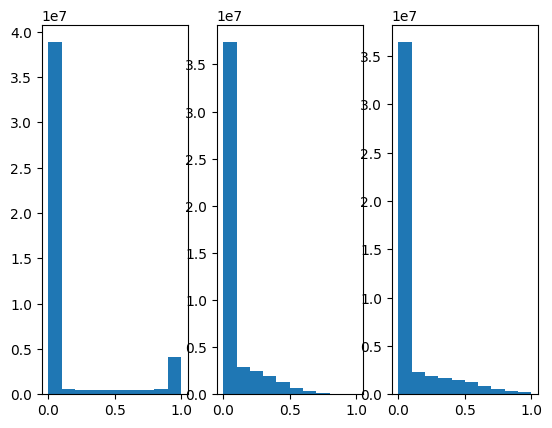

In [54]:
fig, axes = plt.subplots(1, 3)

axes[0].hist(x_train_original.flatten())
axes[1].hist(x_train_reconstructed.flatten())
axes[2].hist(x_train_reconstructed_renorm.flatten())

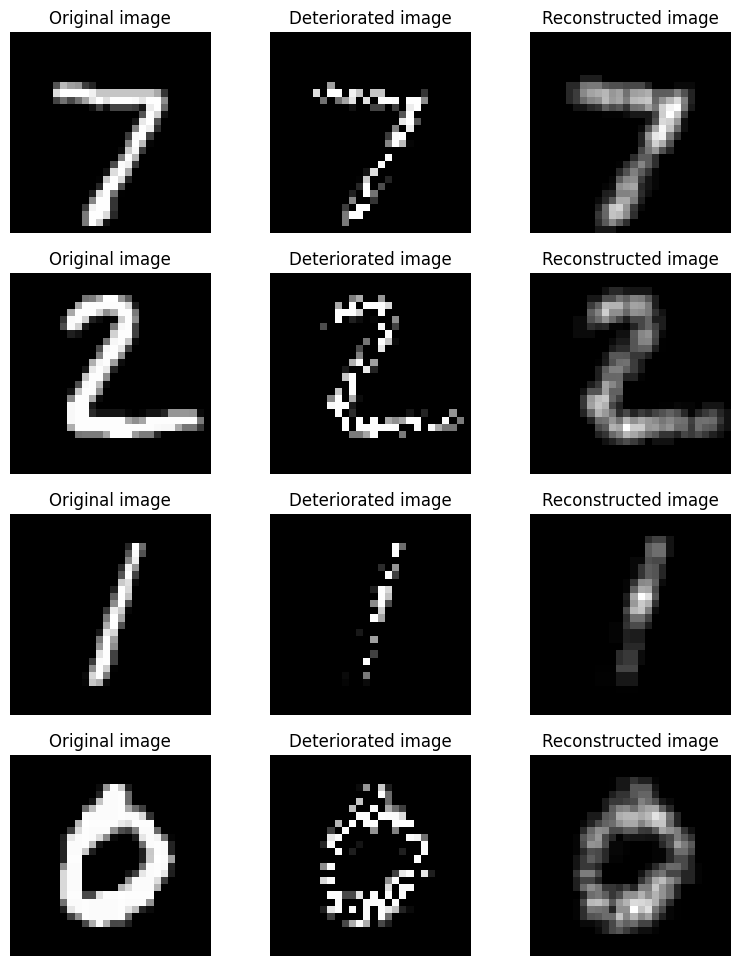

In [57]:
plot_original_deteriorated_reconstructed_images(x_val_original[:4, ...], x_val_deteriorated[:4, ...], x_val_reconstructed_renorm[:4, ...])

In [60]:
mse_train_renorm = 1 / (x_train_original.shape[0] * x_train_original.shape[2] * x_train_original.shape[3]) * (x_train_original - x_train_reconstructed_renorm).pow(2).sum()
mse_val_renorm = 1 / (x_val_original.shape[0] * x_val_original.shape[2] * x_val_original.shape[3]) * (x_val_original - x_val_reconstructed_renorm).pow(2).sum()

print(f"training MSE: {mse_train_renorm}")
print(f"validation MSE: {mse_val_renorm}")

training MSE: 0.03148898854851723
validation MSE: 0.0319063775241375


**Answer**: The mse has improved somewhat but not by much. The renormalization is still not able to nullify the darkening which occurred due to the application of the uniform kernel.

We will now try another, slightly more advanced approach to make the pixel distribution of the reconstructed images closer to that of the original images.
For this, we will use **quantile transformation**.

On the training set, we learn:
* $T_1$: the transformation that goes from the pixel distribution of the original images to a uniform distribution, and
* $T_2$: the transformation that goes from the pixel distribution of the reconstructed images to a uniform distribution.

Then, to transform the reconstructed images so that the distribution of their pixels follows the distribution of the pixels of the original images, we apply the transformation $T_1^{-1} \circ T_2$ to the reconstructed images.

The code below applies these transformations to the training and validation sets:

In [62]:
from sklearn.preprocessing import QuantileTransformer


qt_train_original = QuantileTransformer(n_quantiles=100, subsample=None)
qt_train_reconstructed = QuantileTransformer(n_quantiles=100, subsample=None)

qt_train_original.fit(x_train_original.ravel().view(-1, 1))
qt_train_reconstructed.fit(x_train_reconstructed.ravel().view(-1, 1))

x_train_reconstructed_quantile = torch.from_numpy(
    qt_train_original.inverse_transform(
        qt_train_reconstructed.transform(x_train_reconstructed.ravel().view(-1, 1))
    ).reshape(x_train_reconstructed.shape)
)

x_val_reconstructed_quantile = torch.from_numpy(
    qt_train_original.inverse_transform(
        qt_train_reconstructed.transform(x_val_reconstructed.ravel().view(-1, 1))
    ).reshape(x_val_reconstructed.shape)
)

### Question 11

1. Display the new pixel distribution on the training set.
2. Display a few transformed reconstructed images on the validation set using the `plot_original_deteriorated_reconstructed_images()` function.
3. Compute the mean squared errors on both sets.
4. Comment on the results obtained.

(array([38839987.,   584688.,   514048.,   447270.,   470007.,   463905.,
          458482.,   531702.,   623746.,  4106165.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

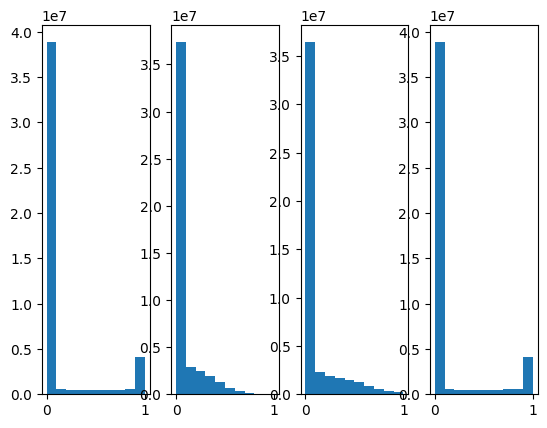

In [63]:
fig, axes = plt.subplots(1, 4)

axes[0].hist(x_train_original.flatten())
axes[1].hist(x_train_reconstructed.flatten())
axes[2].hist(x_train_reconstructed_renorm.flatten())
axes[3].hist(x_train_reconstructed_quantile.flatten())

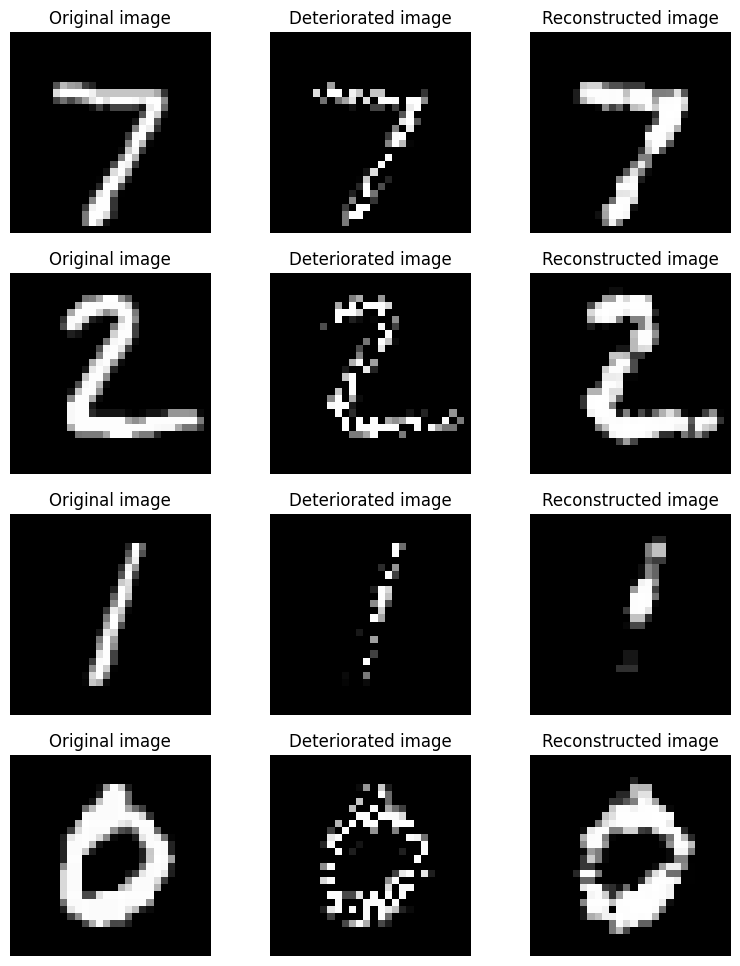

In [64]:
plot_original_deteriorated_reconstructed_images(x_val_original[:4, ...], x_val_deteriorated[:4, ...], x_val_reconstructed_quantile[:4, ...])

In [65]:
mse_train_quantile= 1 / (x_train_original.shape[0] * x_train_original.shape[2] * x_train_original.shape[3]) * (x_train_original - x_train_reconstructed_quantile).pow(2).sum()
mse_val_quantile = 1 / (x_val_original.shape[0] * x_val_original.shape[2] * x_val_original.shape[3]) * (x_val_original - x_val_reconstructed_quantile).pow(2).sum()

print(f"training MSE: {mse_train_quantile}")
print(f"validation MSE: {mse_val_quantile}")

training MSE: 0.02642235270525256
validation MSE: 0.026215752835686758


**Answer**: the obtained results are much better and the darkening effect has been reverted, however the method struggles in areas where the deterioration is quite dense and if the original lines were quite thin. Overall, it has achieved lower mse than all methods tried.

We will now try a convolutional neural network approach.

### Question 12

Create the *dataloaders* for the training and validation sets using the [`torch.utils.data.DataLoader()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) class with batches of size $32$. Don't forget to shuffle the observations for the training set, but not for the validation set. To create the datasets, use the [`torch.utils.data.TensorDataset()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.TensorDataset) class. **Each dataset must contain both the deteriorated images and the original images**.

In [71]:
from torch.utils.data import TensorDataset, DataLoader

dataset_train_deteriorated = TensorDataset(x_train_deteriorated)
dataset_val_deteriorated = TensorDataset(x_val_deteriorated)

train_deteriorated = DataLoader(dataset_train_deteriorated, batch_size=32, shuffle=True)
val_deteriorated = DataLoader(dataset_val_deteriorated, batch_size=32, shuffle=False)

## Architecture

We will use an autoencoder-type architecture, composed of an encoder and a decoder.

The encoder will have the following sequential architecture:

* Two-dimensional convolution with $32$ output channels, a kernel of size $3 \times 3$, and padding of $1$.
* ReLU activation function.
* Max pooling with a kernel of size $2 \times 2$.
* Two-dimensional convolution with $16$ output channels, a kernel of size $3 \times 3$, and padding of $1$.
* ReLU activation function.
* Max pooling with a kernel of size $2 \times 2$.
* Two-dimensional convolution with $8$ output channels, a kernel of size $3 \times 3$, and padding of $1$.
* ReLU activation function.
* Max pooling with a kernel of size $2 \times 2$.

The decoder will have the following sequential architecture:

* Transposed convolution with $8$ output channels, a kernel of size $3 \times 3$, and a stride of size $2$.
* ReLU activation function.

* Transposed convolution with $16$ output channels, a kernel of size $2 \times 2$, and a stride of size $2$.
* ReLU activation function.

* Transposed convolution with $32$ output channels, a kernel of size $2 \times 2$, and a stride of size $2$.
* ReLU activation function.

* Convolution with $1$ output channel, a kernel of size $3 \times 3$, and padding of $1$.
* Sigmoid activation function.

Here are the links to the documentation of the relevant classes:
[`torch.nn.Conv2d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html),
[`torch.nn.ReLU()`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html),
[`torch.nn.MaxPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html),
[`torch.nn.ConvTranspose2d()`](https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and
[`torch.nn.Sigmoid()`](https://pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html).

        
### Question 13

Complete the missing code in the `__init__()`, `forward()`, `step()`, and `configure_optimizers()` methods of the `DenoisingAutoencoder()` class using the following information:
* `__init__()`: you need to:
    + instantiate all the layers and activation functions of the architecture,
    + define the loss function (we will use the mean squared error).
* `forward()`: you need to define the forward pass, i.e., how to go from the inputs (the damaged images) to the outputs (the reconstructed images).
* `step()`: given a batch of observations (`batch`), you need to:
    + retrieve the inputs (the damaged images) and the true outputs (the original images),
    + perform a forward pass to retrieve the reconstructed images,
    + compute the loss function between the reconstructed images and the original images (`loss`).
* `configure_optimizers()`: we will use the *Adam* optimization algorithm with the default values for its hyperparameters.

In [76]:
import lightning as L


class DenoisingAutoencoder(L.LightningModule):  # Always inherit from the lightning.LightningModule class

    def __init__(self):
        """Constructor.

        In the constructor, we always run the constructor of the parent class and we
        instantiate all the elements of our network: the layers, the activation functions,
        the loss function and the metrics.
        """
        super().__init__()  # Always run the constructor of the parent class

        ### BEGIN TODO ###
        # Instantiate the layers and activation functions
        self.encoder = torch.nn.Sequential(
            torch.nn.Conv2d(1, 32, 3, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(2),
            torch.nn.Conv2d(32, 16, 3, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(2),
            torch.nn.Conv2d(16, 8, 3, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(2)
        )

        self.decoder = torch.nn.Sequential(
            torch.nn.ConvTranspose2d(8, 8, 3, stride=2),
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(8, 16, 2, stride=2),
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(16, 32, 2, stride=2),
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(32, 1, 3, padding=1),
            torch.nn.Sigmoid()
        )

        # Instantiate the loss function
        self.loss = torch.nn.MSELoss()
        #### END TODO ####

    def forward(self, x_deteriorated):
        """Performs the forward pass.

        Parameters
        ----------
        x_deteriorated : Tensor, shape = (batch_size, n_channels, height, width)
            Deteriorated images.

        Returns
        -------
        x_reconstructed : Tensor, shape = (batch_size, n_channels, height, width)
            Reconstructed images.
        """
        ### BEGIN TODO ###
        x_reconstructed = self.decoder(self.encoder(x_deteriorated))
        #### END TODO ####
        return x_reconstructed

    def step(self, batch, dataset):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : list[Tensor, Tensor]
            Batch of samples. The first tensor consists of the deteriorated images,
            while the second tensor consists of the original images.

        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        ### BEGIN TODO ###
        reconstruct = self.forward(batch[0])
        loss = self.loss(reconstruct, batch[1])
        #### END TODO ###

        if dataset == "training":
            name = "train"
            bar_step = True
        else:
            name = "val"
            bar_step = False

        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            --------------------------------
            |   Data set   | Loss function |
            | ------------ | ------------- |
            |   Training   |{metrics['loss_train'].item():^15.5f}|
            |  Validation  |{metrics['loss_val'].item():^15.5f}|
            --------------------------------
        """)
        string = "\n".join([line.strip() for line in string.split("\n")])
        print(string)

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        ### BEGIN TODO ###
        optimizer = torch.optim.Adam(self.parameters)
        #### END TODO ####
        return optimizer

### Question 14

Display a summary of your architecture. How many trainable parameters does it have?

In [77]:
from torchinfo import summary

summary(DenoisingAutoencoder(), input_size=(32, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
DenoisingAutoencoder                     [32, 1, 28, 28]           --
├─Sequential: 1-1                        [32, 8, 3, 3]             --
│    └─Conv2d: 2-1                       [32, 32, 28, 28]          320
│    └─ReLU: 2-2                         [32, 32, 28, 28]          --
│    └─MaxPool2d: 2-3                    [32, 32, 14, 14]          --
│    └─Conv2d: 2-4                       [32, 16, 14, 14]          4,624
│    └─ReLU: 2-5                         [32, 16, 14, 14]          --
│    └─MaxPool2d: 2-6                    [32, 16, 7, 7]            --
│    └─Conv2d: 2-7                       [32, 8, 7, 7]             1,160
│    └─ReLU: 2-8                         [32, 8, 7, 7]             --
│    └─MaxPool2d: 2-9                    [32, 8, 3, 3]             --
├─Sequential: 1-2                        [32, 1, 28, 28]           --
│    └─ConvTranspose2d: 2-10             [32, 8, 7, 7]             584
│    └─

**Answer**: TODO

### Question 15

Train your model for $10$ epochs.

In [ ]:
# TODO

We retrieve all the images reconstructed by the neural network on the validation set:

In [ ]:
model.eval()
with torch.no_grad():
    x_val_reconstructed_dae = model(x_val_deteriorated.to(model.device)).cpu()

### Question 16

Using the `plot_original_deteriorated_reconstructed_images()` function, display a few images reconstructed by the neural network on the validation set.

In [ ]:
# TODO

### Question 17

Which is the best model among the different approaches tried? Justify your answer.

**Answer**: TODO